# Baseline 2 — Exp09 diagnostic audit (no training)

**Purpose:** quantify class imbalance, per-class accuracy, frequent confusions and (optionally) compare **9,625 all-pairs** against a **pre-approved 333-pair catalogue** using the **same checkpoint**, **same validation images**, and **no model retraining**.

- Put this notebook alongside `evaluate.py` and `model_resnet50.py` in `C:\AML\ML_Project\Baseline2` and run it with the working CUDA kernel.
- It reads `splits_v2/` and the **already saved** `outputs/b2_resnet50_exp09_b1matched_seed42/` checkpoint/predictions. It never reads official test files and never modifies your Exp09 checkpoint.
- It writes CSV/PNG reports only into `outputs/exp09_audit/`.
- The optional 333-pair experiment is **OFF** until you obtain a group-approved catalogue with columns `crop_id,disease_id`. Do **not** construct it from official test labels, or from the held-out answers solely to raise validation accuracy.
- For the main B1 vs B2 comparison, retain the same **9,625 all-pairs protocol** used in both original baselines. A restricted catalogue is a separate analysis/protocol.

## 1 — Setup and verify your saved Exp09 predictions

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from evaluate import validate_development_splits, make_candidates, require_candidate_coverage, composition_scores

PROJECT_DIR = Path.cwd()
SPLIT_DIR = PROJECT_DIR / "splits_v2"
IMAGE_ROOT = PROJECT_DIR.parent / "DPD_Small_dataset"
EXP09_DIR = PROJECT_DIR / "outputs" / "b2_resnet50_exp09_b1matched_seed42"
AUDIT_DIR = PROJECT_DIR / "outputs" / "exp09_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

frames, report = validate_development_splits(SPLIT_DIR)
assert len(frames['train_fit']) == 6905
predictions = {}
for split in ('val_seen', 'val_unseen'):
    path = EXP09_DIR / f"{split}_error_predictions.csv"
    if not path.is_file():
        raise FileNotFoundError(f"Run Section 8 of Exp09 first: {path}")
    pred = pd.read_csv(path)
    assert pred.filename.is_unique
    assert set(pred.filename) == set(frames[split].filename), f"Wrong {split} files"
    predictions[split] = pred

assert (EXP09_DIR / 'best_development.pt').is_file(), 'Exp09 checkpoint missing'
print('Verified original split and saved predictions. No training or official test data used.')
print('Output directory:', AUDIT_DIR)


Verified original split and saved predictions. No training or official test data used.
Output directory: c:\AML\ML_Project\Baseline2\outputs\exp09_audit


## 2 — Class counts (training only) and imbalance

Report **both crop and disease label frequencies**, as well as train-fit **crop–disease composition** frequencies. A class with only 5 examples should not be compared to a 1,000-image class as if the supports were equal. Do not assume your lecturer’s carrot/tomato numbers are true until measured here.


CROP — 55 classes/pairs; train min=2, median=38, max=1007
Least frequent 10:


,crop_name,train_images,val_seen_images,val_unseen_images
1,apricot,2,2,0
31,maple,2,1,0
10,cabbage,3,2,0
11,carrot,3,2,0
15,celery,3,1,0
8,brassica,4,1,0
26,ginger,4,2,0
52,walnut,4,1,0
9,broccoli,5,1,0
24,eggplant,5,3,0


Most frequent 10:


,crop_name,train_images,val_seen_images,val_unseen_images
51,tomato,1007,87,70
13,cassava,959,84,117
0,apple,924,83,9
21,corn,833,77,0
33,paddy,527,49,0
44,soybean,343,33,0
18,citrus,207,20,0
27,grape,152,15,0
47,sugarcane,147,15,0
40,potato,133,12,70



DISEASE — 175 classes/pairs; train min=1, median=8, max=1417
Least frequent 10:


,disease_name,train_images,val_seen_images,val_unseen_images
42,alternaria_leaf_blight,1,1,0
96,apoderus_javanicus,1,1,0
97,aulacaspis_tubercularis,1,0,0
54,bacterial_soft_rot,1,0,0
160,blue_mold,1,1,0
38,botrytis_blight,1,0,0
64,brown_eye_spot,1,1,0
43,cavity_spot,1,1,0
99,ceroplastes_rubens,1,0,0
69,chlorotic_leaf_spot,1,0,0


... (2 outputs left out)


COMPOSITION — 313 classes/pairs; train min=1, median=6, max=500
Least frequent 10:


,composition_name,train_images,val_seen_images,val_unseen_images
16,apricot_coryneum_blight,1,1,0
17,apricot_monillia_laxa,1,1,0
21,banana_cigar_end_rot,1,1,0
33,bean_halo_blight,1,1,0
47,blueberry_botrytis_blight,1,0,0
48,blueberry_mummy_berry,1,1,0
49,blueberry_rust,1,0,0
50,blueberry_scorch,1,0,0
53,broccoli_downy_mildew,1,0,0
54,broccoli_ring_spot,1,0,0


Most frequent 10:


,composition_name,train_images,val_seen_images,val_unseen_images
68,cassava_mosaic,500,44,0
9,apple_healthy,213,18,0
102,corn_healthy,205,18,0
152,corn_streak_virus,201,17,0
87,citrus_greening,179,16,0
245,soybean_healthy,176,15,0
297,tomato_yellow_leaf_curl_virus,164,14,0
294,tomato_septoria_leaf_spot,164,14,0
67,cassava_healthy,140,12,0
10,apple_rust,126,11,0


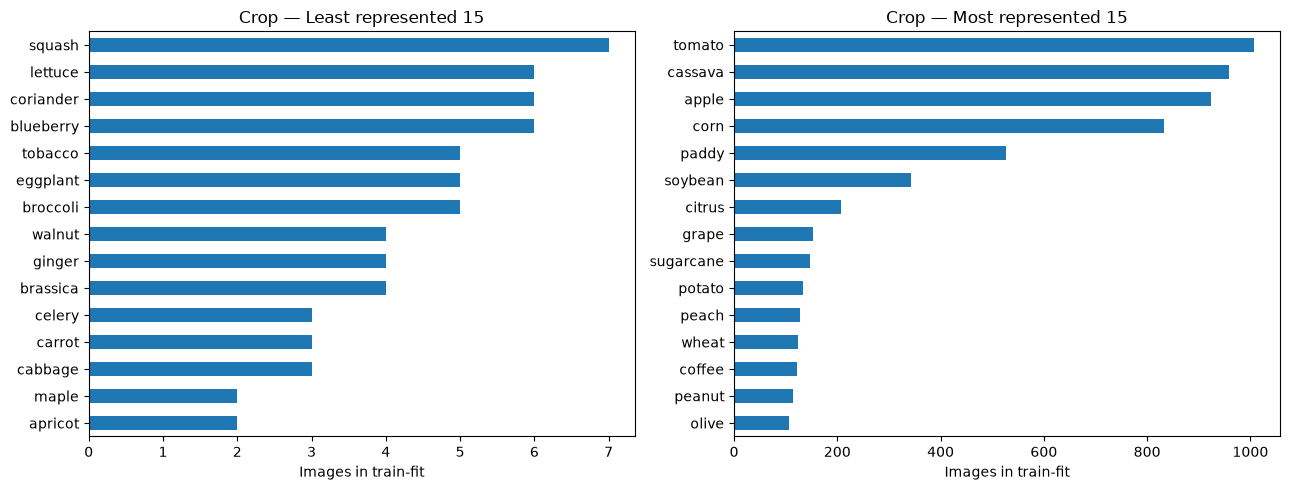

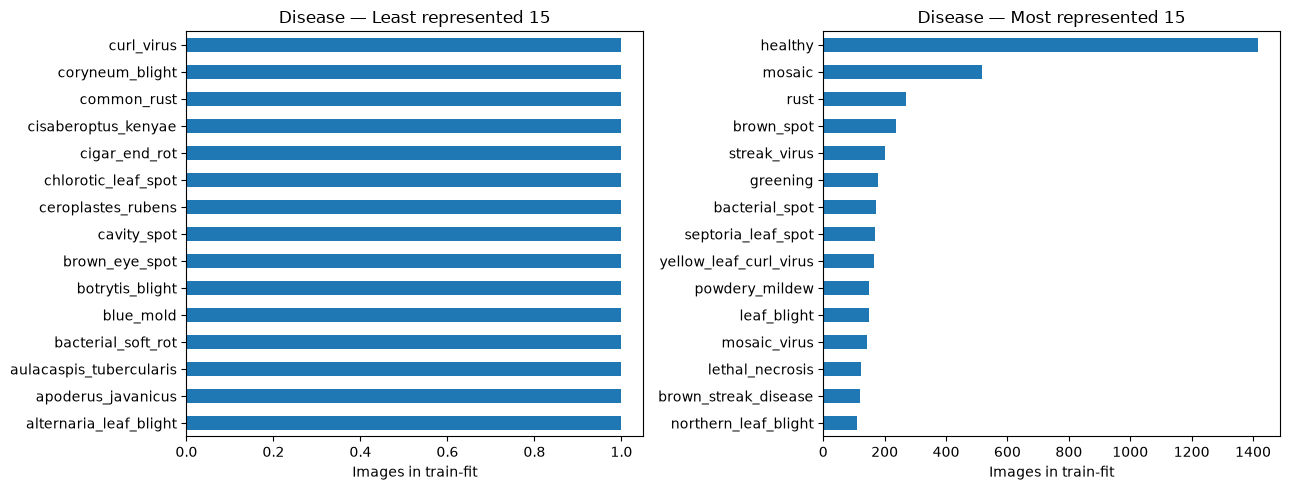

In [2]:
class_counts = {}
for task in ('crop','disease','composition'):
    key, name = f'{task}_id', f'{task}_name'
    table = (frames['train_fit'].groupby([key, name], dropna=False)
             .size().rename('train_images').reset_index()
             .sort_values(['train_images',name], ascending=[True,True]))
    for split in ('val_seen', 'val_unseen'):
        count = frames[split].groupby(key).size().rename(f'{split}_images')
        table = table.join(count, on=key)
    table[['val_seen_images','val_unseen_images']] = table[['val_seen_images','val_unseen_images']].fillna(0).astype(int)
    class_counts[task] = table
    table.to_csv(AUDIT_DIR / f'{task}_class_counts.csv', index=False)
    print(f'\n{task.upper()} — {len(table)} classes/pairs; train min={table.train_images.min()}, median={table.train_images.median():g}, max={table.train_images.max()}')
    print('Least frequent 10:')
    display(table[[name,'train_images','val_seen_images','val_unseen_images']].head(10))
    print('Most frequent 10:')
    display(table[[name,'train_images','val_seen_images','val_unseen_images']].tail(10).iloc[::-1])

for task in ('crop','disease'):
    tab = class_counts[task]
    name = f'{task}_name'
    fig, axes = plt.subplots(1,2,figsize=(13,5))
    for ax, part, title in zip(axes, [tab.head(15),tab.tail(15)], ['Least represented 15','Most represented 15']):
        part.sort_values('train_images').plot.barh(x=name,y='train_images',ax=ax,legend=False)
        ax.set(title=f'{task.title()} — {title}',xlabel='Images in train-fit',ylabel='')
    fig.tight_layout()
    fig.savefig(AUDIT_DIR / f'{task}_train_count_extremes.png',dpi=150,bbox_inches='tight')
    plt.show()


## 3 — Per-class Top-1, weakest / strongest, support

These are individual **head** Top-1 accuracies, not composition Top-1. Set `MIN_SUPPORT=5` so one-image classes do not misleadingly dominate the strongest/weakest rankings. Include `n_validation` in every chart/table. Compare **train-fit** counts with accuracy but do not assert a causal relationship from correlation alone.

In [3]:
MIN_SUPPORT = 5
per_class = {}
for split, pred in predictions.items():
    for task in ('crop','disease'):
        idcol, namecol = f'{task}_id', f'{task}_name'
        predicted_col = f'predicted_{task}_id'
        rows = pred.assign(_correct=(pred[idcol]==pred[predicted_col]).astype(int))
        score = (rows.groupby(idcol).agg(n_validation=(idcol,'size'),
                  n_correct=('_correct','sum')).reset_index())
        score['top1_accuracy'] = score.n_correct / score.n_validation
        freq = class_counts[task][[idcol,namecol,'train_images']]
        score = score.merge(freq,on=idcol,how='left',validate='one_to_one')
        score['n_wrong'] = score.n_validation-score.n_correct
        err = rows.loc[~rows._correct.astype(bool)]
        worst_wrong = (err.groupby([idcol,predicted_col]).size().rename('mistake_count')
                       .reset_index().sort_values('mistake_count',ascending=False)
                       .drop_duplicates(idcol))
        name_map = dict(zip(freq[idcol],freq[namecol]))
        worst_wrong['most_common_wrong_prediction'] = worst_wrong[predicted_col].map(name_map)
        score = score.merge(worst_wrong[[idcol,'most_common_wrong_prediction','mistake_count']],on=idcol,how='left')
        score = score.sort_values(['top1_accuracy','n_validation'],ascending=[True,False])
        per_class[(split,task)] = score
        score.to_csv(AUDIT_DIR / f'{split}_{task}_per_class.csv',index=False)
        eligible = score[score.n_validation>=MIN_SUPPORT]
        print(f'\n{split}: {task} head, {len(score)} labels represented, {len(eligible)} with n >= {MIN_SUPPORT}')
        print('Weakest 10:')
        display(eligible[[namecol,'train_images','n_validation','top1_accuracy','most_common_wrong_prediction']].head(10))
        print('Strongest 10:')
        display(eligible.sort_values(['top1_accuracy','n_validation'],ascending=[False,False])[
            [namecol,'train_images','n_validation','top1_accuracy','most_common_wrong_prediction']].head(10))



val_seen: crop head, 55 labels represented, 27 with n >= 5
Weakest 10:


,crop_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
4,bean,27,5,0.400000,corn
5,pepper_bell,56,7,0.714286,tomato
38,pear,94,9,0.777778,apple
49,tea,40,9,0.777778,tomato
19,coffee,121,14,0.785714,citrus
6,blackgram,49,5,0.800000,tobacco
22,cotton,51,5,0.800000,cucumber
30,mango,100,16,0.812500,apple
28,guava,38,6,0.833333,strawberry
36,peach,128,14,0.857143,guava


Strongest 10:


,crop_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
47,sugarcane,147,15,1.000000,NaN
53,wheat,124,13,1.000000,NaN
40,potato,133,12,1.000000,NaN
32,olive,107,10,1.000000,NaN
37,peanut,114,9,1.000000,NaN
35,papaya,57,5,1.000000,NaN
41,pumpkin,55,5,1.000000,NaN
46,strawberry,57,5,1.000000,NaN
51,tomato,1007,87,0.988506,cassava
13,cassava,959,84,0.988095,mango



val_seen: disease head, 155 labels represented, 39 with n >= 5
Weakest 10:


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
48,green_mottle,59,5,0.000000,mosaic
53,spot,83,12,0.416667,bacterial_spot
11,marssonina_blotch,75,7,0.428571,rust
106,hispa,67,6,0.500000,blast
28,downy_mildew,58,11,0.545455,tungro
146,septoria_leaf_spot,167,15,0.600000,leaf_blight
54,curl,42,5,0.600000,scab
109,tungro,59,5,0.600000,blast
8,grey_spot,69,6,0.666667,alternaria_blotch
46,brown_streak_disease,120,10,0.700000,brown_leaf_spot


... (6 outputs left out)


val_unseen: disease head, 8 labels represented, 8 with n >= 5
Weakest 10:


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
4,bacterial_blight,27,117,0.000000,brown_spot
5,spider_mites,5,70,0.000000,target_spot
3,angular_leaf_spot,7,18,0.000000,bean_rust
6,bacterial_leaf_streak,12,5,0.000000,rust
1,monillia_laxa,8,9,0.111111,eriosoma_lanigerum
7,late_blight,103,70,0.228571,early_blight
2,powdery_mildew,150,60,0.400000,sooty_mould
0,healthy,1417,51,0.921569,mosaic


Strongest 10:


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
0,healthy,1417,51,0.921569,mosaic
2,powdery_mildew,150,60,0.400000,sooty_mould
7,late_blight,103,70,0.228571,early_blight
1,monillia_laxa,8,9,0.111111,eriosoma_lanigerum
4,bacterial_blight,27,117,0.000000,brown_spot
5,spider_mites,5,70,0.000000,target_spot
3,angular_leaf_spot,7,18,0.000000,bean_rust
6,bacterial_leaf_streak,12,5,0.000000,rust


## 4 — Confusion matrices, with readable weak/strong-class plots

All true class × predicted class counts are saved as **full CSV confusion matrices**. To avoid unreadable 175×175 graphics, the plots display the **weakest and strongest classes** (by each split’s validation accuracy, with at least 5 images). The heatmaps show `Correct`, the five most frequent specific wrong predictions, and `Other wrong`. Each row still adds up to its true image count.

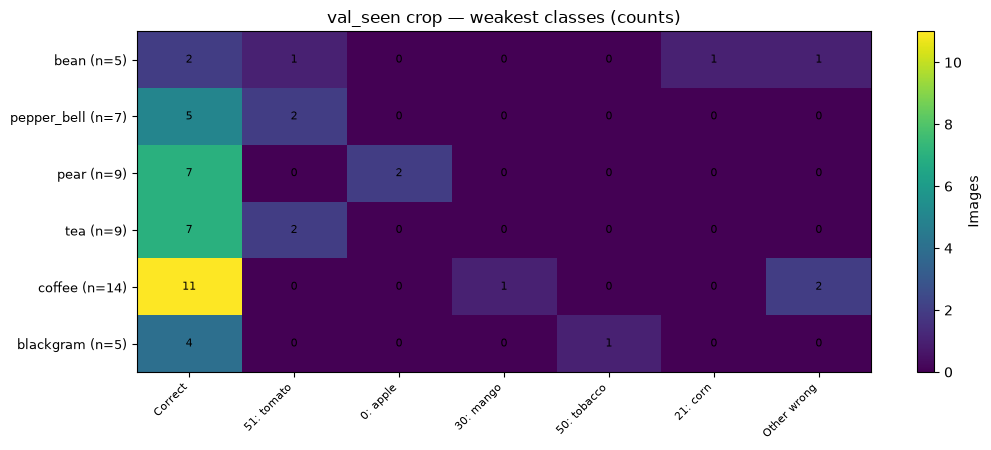

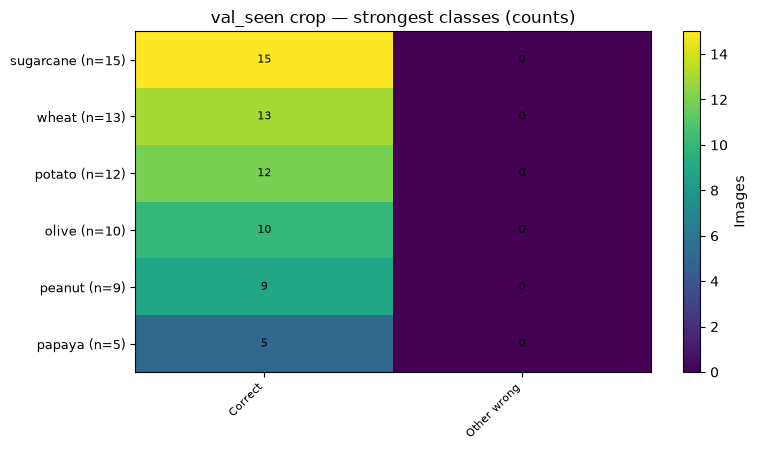

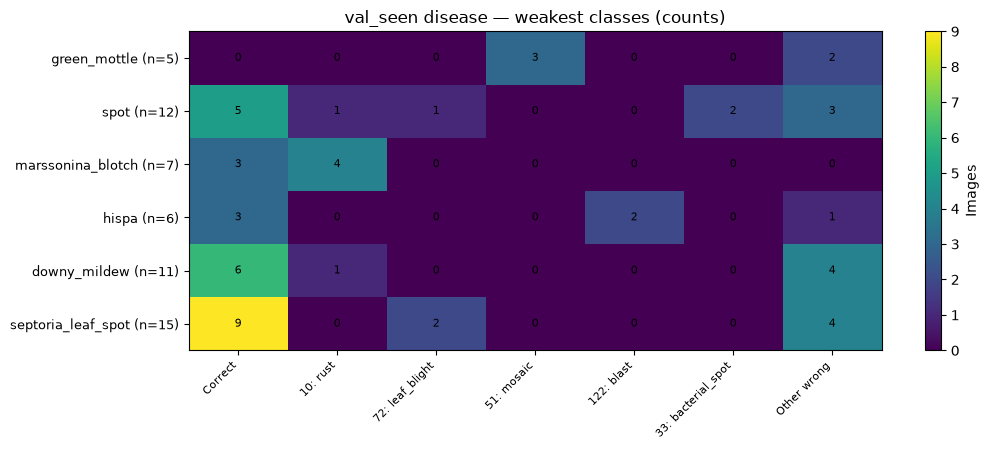

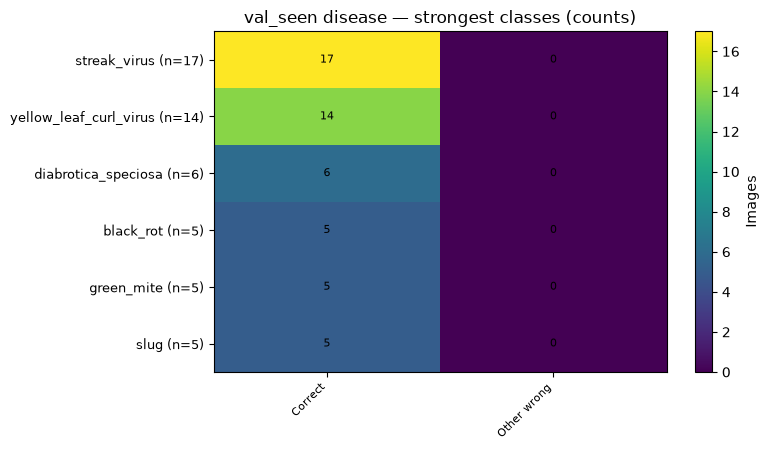

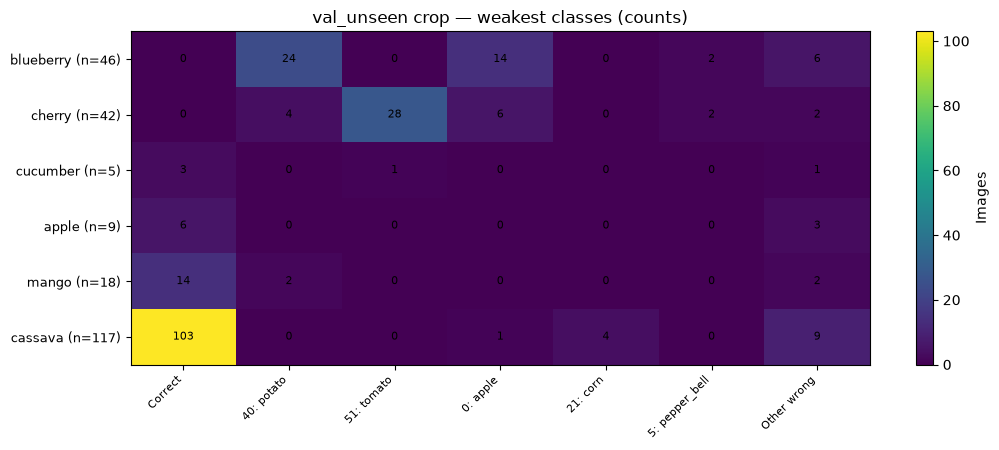

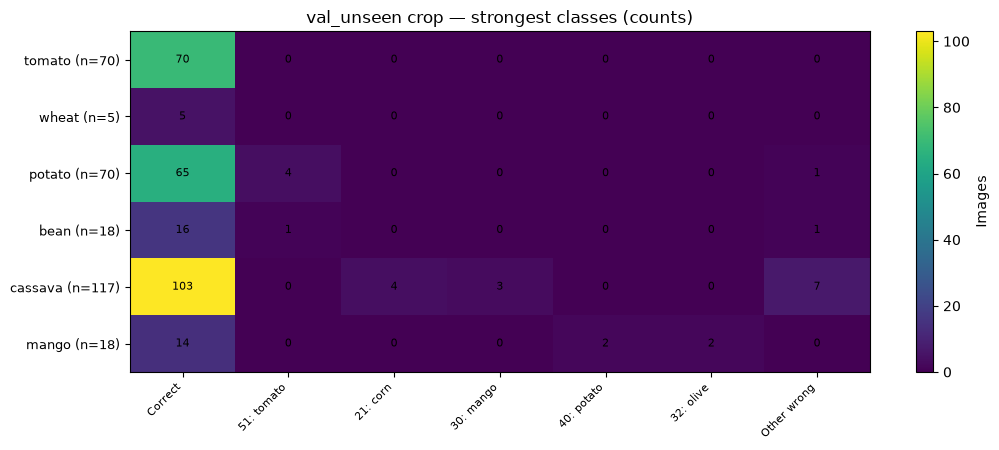

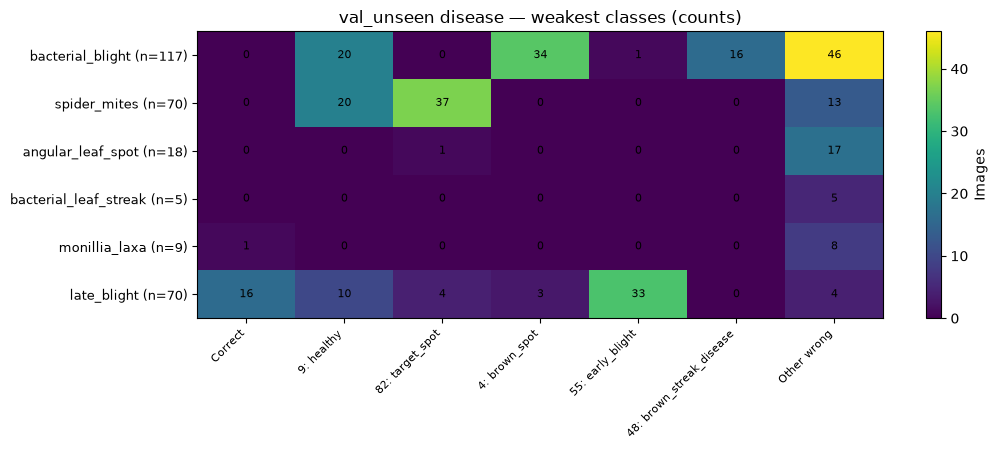

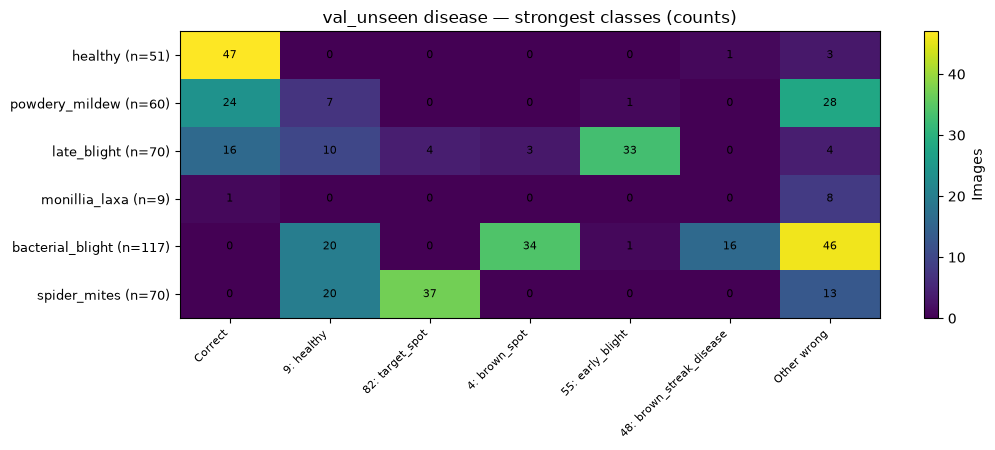

In [5]:
for split, pred in predictions.items():
    for task in ('crop','disease'):
        idcol, namecol = f'{task}_id', f'{task}_name'
        predcol = f'predicted_{task}_id'
        freq = class_counts[task]
        name_map = dict(zip(freq[idcol],freq[namecol]))
        full = pd.crosstab(pred[idcol], pred[predcol])
        ids = sorted(freq[idcol].unique())
        full = full.reindex(index=ids,columns=ids,fill_value=0)
        full.index = [f'{i}: {name_map[i]}' for i in ids]
        full.columns = [f'{i}: {name_map[i]}' for i in ids]
        full.to_csv(AUDIT_DIR / f'{split}_{task}_full_confusion.csv')
        qualified = per_class[(split,task)].query('n_validation >= @MIN_SUPPORT')
        weak = qualified.head(6)
        strong = qualified.sort_values(['top1_accuracy','n_validation'],ascending=[False,False]).head(6)
        for label, selected in [('weakest',weak),('strongest',strong)]:
            selected_ids = selected[idcol].to_list()
            small = pred.loc[pred[idcol].isin(selected_ids),[idcol,predcol]].copy()
            wrong = small.loc[small[idcol]!=small[predcol]]
            common = wrong[predcol].value_counts().head(5).index.tolist()
            pretty_cols = ['Correct'] + [f'{int(p)}: {name_map.get(int(p),str(p))}' for p in common] + ['Other wrong']
            counts = []
            row_labels = []
            for target in selected_ids:
                part = small[small[idcol]==target]
                vals = [int((part[predcol]==target).sum())]
                vals += [
                    int(((part[predcol] == p) & (part[predcol] != target)).sum())
                    for p in common
                ]
                vals.append(int(((part[predcol]!=target)&~part[predcol].isin(common)).sum()))
                assert sum(vals)==len(part)
                counts.append(vals)
                row_labels.append(f'{name_map[target]} (n={len(part)})')
            condensed = pd.DataFrame(counts,index=row_labels,columns=pretty_cols)
            condensed.to_csv(AUDIT_DIR / f'{split}_{task}_{label}_confusion_summary.csv')
            fig,ax = plt.subplots(figsize=(max(8,2+len(pretty_cols)*1.25),max(4,len(selected_ids)*0.6+1)))
            im = ax.imshow(condensed.to_numpy(),aspect='auto')
            ax.set_xticks(np.arange(len(condensed.columns)),labels=condensed.columns,rotation=45,ha='right',fontsize=8)
            ax.set_yticks(np.arange(len(condensed.index)),labels=condensed.index,fontsize=9)
            for (i,j),val in np.ndenumerate(condensed.to_numpy()):
                ax.text(j,i,str(val),ha='center',va='center',fontsize=8)
            ax.set_title(f'{split} {task} — {label} classes (counts)')
            fig.colorbar(im,ax=ax,label='Images')
            fig.tight_layout()
            fig.savefig(AUDIT_DIR / f'{split}_{task}_{label}_confusion_summary.png',dpi=150,bbox_inches='tight')
            plt.show()


## 5 — Optional: compare all 9,625 candidate pairs against a pre-approved 333-pair catalogue (NO RETRAINING)

**OFF by default.** You must first obtain a legitimate, label-independent, group-approved file `candidate_333_approved.csv` with exactly two integer columns `crop_id,disease_id` and 333 unique rows. It must include **every ground-truth development composition** and must **not** be constructed from official test labels or validation answers merely to increase the score. Confirm that restricted-candidate evaluation is allowed by the assignment and separately label it as a closed-world/feasibility-constrained protocol. Keep 9,625 all-pairs as the original baseline protocol.

When approved, this cell performs **forward inference once per validation batch** and ranks the same crop/disease logits against both candidate sets. It only changes **postprocessing**, not CNN weights, data split, heads or training.

In [ ]:
RUN_APPROVED_333_COMPARISON = False  # IMPORTANT: leave False until catalogue and evaluation protocol are approved
APPROVED_CATALOG_CSV = PROJECT_DIR / 'candidate_333_approved.csv'

if RUN_APPROVED_333_COMPARISON:
    import torch
    from torch.utils.data import DataLoader
    from model_resnet50 import load_resnet50_checkpoint
    from evaluate import DPDDataset, harmonic_mean
    # Adopt the actual Exp09 validation preprocessing (bilinear, resize-256, crop-224).
    from torchvision import transforms as T
    from torchvision.transforms import InterpolationMode
    from evaluate import MEAN, STD
    def fixed_eval_transform():
        return T.Compose([T.Resize(256,interpolation=InterpolationMode.BILINEAR),T.CenterCrop(224),
                          T.ToTensor(),T.Normalize(MEAN,STD)])
    if not APPROVED_CATALOG_CSV.is_file():
        raise FileNotFoundError('No approved 333-pair CSV: do not generate one from official test labels.')
    candidates_333 = make_candidates('catalog',APPROVED_CATALOG_CSV)
    assert len(candidates_333)==333, f'Expected exactly 333; got {len(candidates_333)}'
    require_candidate_coverage(candidates_333,list(frames.values()))
    candidates_all = make_candidates('all_pairs')
    import hashlib
    checkpoint = EXP09_DIR / 'best_development.pt'
    model, state = load_resnet50_checkpoint(checkpoint, 'cuda' if torch.cuda.is_available() else 'cpu')
    assert state['development_split']['sha256'] == report['sha256'], 'Split hashes changed'
    assert state['config']['image_size']==224
    device=next(model.parameters()).device
    results=[]
    catalog_sha=hashlib.sha256(APPROVED_CATALOG_CSV.read_bytes()).hexdigest()
    with torch.inference_mode():
        for split in ('val_seen','val_unseen'):
            loader=DataLoader(DPDDataset(frames[split],IMAGE_ROOT,fixed_eval_transform()),batch_size=16,
                              shuffle=False,num_workers=0,pin_memory=(device.type=='cuda'))
            counts={name:{'top1':0,'top5':0} for name in ('all_9625','approved_333')}
            total=0
            for batch in loader:
                x=batch['image'].to(device,non_blocking=True)
                truth=torch.stack((batch['crop'],batch['disease']),dim=1).to(device)
                with torch.autocast(device_type=device.type,enabled=device.type=='cuda'):
                    output=model(x)
                total+=len(x)
                for name,pairs in (('all_9625',candidates_all),('approved_333',candidates_333)):
                    pairs=pairs.to(device)
                    indices=composition_scores(output['crop_logits'],output['disease_logits'],pairs).topk(5,dim=1).indices
                    ranking=pairs[indices]
                    matches=(ranking==truth[:,None,:]).all(dim=2)
                    counts[name]['top1']+=int(matches[:,0].sum())
                    counts[name]['top5']+=int(matches.any(dim=1).sum())
            for name,cnt in counts.items():
                results.append({'protocol':name,'split':split,'n':total,
                                'composition_top1':cnt['top1']/total,'composition_top5':cnt['top5']/total,
                                'correct_top1':cnt['top1'],'candidate_catalog_sha256':catalog_sha})
    cmp=pd.DataFrame(results)
    for protocol in ('all_9625','approved_333'):
        row=cmp[cmp.protocol==protocol].set_index('split')
        hm=harmonic_mean(row.loc['val_seen','composition_top1'],row.loc['val_unseen','composition_top1'])
        cmp.loc[cmp.protocol==protocol,'composition_hm']=hm
    display(cmp)
    cmp.to_csv(AUDIT_DIR/'candidate_9625_vs_333_development.csv',index=False)
    print('Same Exp09 weights, new candidate ranking only. This does not prove better learned disease features.')
else:
    print('333-candidate analysis disabled. No catalogue, official tests or new training were accessed.')


## How to report this audit

- Report actual **train-fit counts** for crop, disease and composition separately. Include median/min/max and the lowest/highest classes.
- State *validation support (n)* beside every per-class Top-1. Classes with tiny n have very uncertain estimates.
- For each split, include **weakest/strongest disease confusion summaries**, plus a few representative misclassified examples if permitted. Do not confuse crop-head/disease-head accuracy with composition accuracy.
- Do not claim frequency caused an error without an ablation. Good follow-up experiments: a single-factor sampler ablation or loss-weight ablation, retaining the same backbone, original split, candidate universe and seed.
- Label the 333 candidate comparison as a **separate protocol** (restricted candidate universe) and never use the official test set to choose its rules. Restricting candidates can improve scores without retraining or improving features.
- The Exp09 Stage 1 checkpoint was selected using development HM. For any final full-data fit, document checkpoint selection separately and ensure the policy is approved before official testing.